# Predict Students' Dropout and Academic Success

**Задача:** определить итоговый академический статус студента - `Dropout`, `Enrolled` или `Graduate`. Доступные для прогноза признаки зависят от этапа обучения.

**Источник:** [UCI Predict Students' Dropout and Academic Success](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success), исходный `data.csv`. CSV должен лежать рядом с ноутбуком. Библиотеки: `pandas`, `matplotlib`, `seaborn`.


## 1. Таблица

Размер, типы, первые строки и описательные статистики.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
df = pd.read_csv("data.csv", sep=";")
print("Размер:", df.shape)
display(df.head())

Размер: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [2]:
display(df.describe(include="all").T.round(2))
print("Входных признаков:", df.shape[1] - 1)
print("Числовых входных:", df.drop(columns="Target").select_dtypes("number").shape[1])

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Marital status,4424.0,NaN,NaN,NaN,1.178571,0.605747,1.0,1.0,1.0,1.0,6.0
Application mode,4424.0,NaN,NaN,NaN,18.669078,17.484682,1.0,1.0,17.0,39.0,57.0
Application order,4424.0,NaN,NaN,NaN,1.727848,1.313793,0.0,1.0,1.0,2.0,9.0
Course,4424.0,NaN,NaN,NaN,8856.642631,2063.566416,33.0,9085.0,9238.0,9556.0,9991.0
Daytime/evening attendance\t,4424.0,NaN,NaN,NaN,0.890823,0.311897,0.0,1.0,1.0,1.0,1.0
Previous qualification,4424.0,NaN,NaN,NaN,4.577758,10.216592,1.0,1.0,1.0,1.0,43.0
Previous qualification (grade),4424.0,NaN,NaN,NaN,132.613314,13.188332,95.0,125.0,133.1,140.0,190.0
Nacionality,4424.0,NaN,NaN,NaN,1.873192,6.914514,1.0,1.0,1.0,1.0,109.0
Mother's qualification,4424.0,NaN,NaN,NaN,19.561935,15.603186,1.0,2.0,19.0,37.0,44.0
Father's qualification,4424.0,NaN,NaN,NaN,22.275316,15.343108,1.0,3.0,19.0,37.0,44.0


Входных признаков: 36
Числовых входных: 36


В таблице 4 424 строки, 36 входных признаков и таргет `Target`. Все входные поля прочитаны как числа, хотя многие обозначают категории. Название `Daytime/evening attendance` содержит завершающий символ табуляции; имя `Nacionality` оставлено как в исходном CSV.

## 2. Таргет

Количество и доли трёх исходов.

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64
Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64


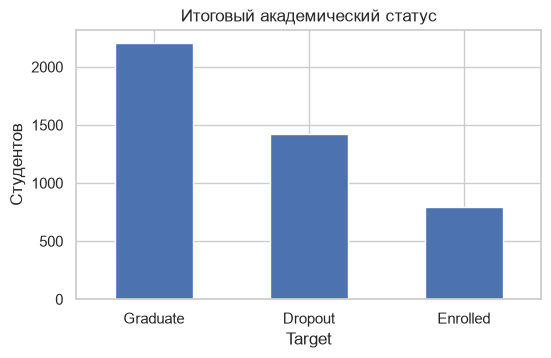

In [3]:
print(df["Target"].value_counts())
print((df["Target"].value_counts(normalize=True) * 100).round(2))
df["Target"].value_counts().plot.bar(figsize=(6, 3.5), rot=0)
plt.title("Итоговый академический статус")
plt.ylabel("Студентов")
plt.show()

`Graduate` - 2 209 (49,93%), `Dropout` - 1 421 (32,12%), `Enrolled` - 794 (17,95%). Исходная постановка - многоклассовая классификация.

## 3. Пропуски и дубликаты

Проверка формальных пропусков, повторов и особенностей имён полей.

In [4]:
print("Всего NaN:", int(df.isna().sum().sum()))
print("Признаков с NaN:", int(df.isna().any().sum()))
print("Полные дубликаты:", int(df.duplicated().sum()))
print("Повторы входных признаков:", int(df.drop(columns="Target").duplicated().sum()))
print("Названия с пробелами по краям:", [repr(c) for c in df if c != c.strip()])

Всего NaN: 0
Признаков с NaN: 0
Полные дубликаты: 0
Повторы входных признаков: 0
Названия с пробелами по краям: ["'Daytime/evening attendance\\t'"]


In [5]:
profile = pd.DataFrame({"Уникальных": df.nunique(),
                        "Нулей": df.select_dtypes("number").eq(0).sum(),
                        "NaN": df.isna().sum()}).fillna(0).astype(int)
display(profile)

,Уникальных,Нулей,NaN
Admission grade,620,0,0
Age at enrollment,46,0,0
Application mode,18,0,0
Application order,8,1,0
Course,17,0,0
Curricular units 1st sem (approved),23,718,0
Curricular units 1st sem (credited),21,3847,0
Curricular units 1st sem (enrolled),23,180,0
Curricular units 1st sem (evaluations),35,349,0
Curricular units 1st sem (grade),805,718,0


Формальных `NaN` и полных дубликатов нет; повторяющихся наборов входных признаков тоже нет. Изменять исходные названия или объединять нули с пропусками оснований нет. По описанию UCI данные уже прошли предварительную обработку до публикации.

## 4. Диапазоны и числовые распределения

Возраст, вступительные баллы и итоги семестров.

In [6]:
fields = ["Age at enrollment", "Admission grade", "Previous qualification (grade)",
          "Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)"]
display(df[fields].describe().round(2).T)
for sem in ["1st", "2nd"]:
    grade = f"Curricular units {sem} sem (grade)"
    approved = f"Curricular units {sem} sem (approved)"
    print(sem, "нулевых оценок:", int(df[grade].eq(0).sum()),
          "из них с нулём одобренных дисциплин:", int((df[grade].eq(0) & df[approved].eq(0)).sum()))

,count,mean,std,min,25%,50%,75%,max
Age at enrollment,4424.0,23.27,7.59,17.0,19.00,20.00,25.00,70.00
Admission grade,4424.0,126.98,14.48,95.0,117.90,126.10,134.80,190.00
Previous qualification (grade),4424.0,132.61,13.19,95.0,125.00,133.10,140.00,190.00
Curricular units 1st sem (grade),4424.0,10.64,4.84,0.0,11.00,12.29,13.40,18.88
Curricular units 2nd sem (grade),4424.0,10.23,5.21,0.0,10.75,12.20,13.33,18.57


1st нулевых оценок: 718 из них с нулём одобренных дисциплин: 718
2nd нулевых оценок: 870 из них с нулём одобренных дисциплин: 870


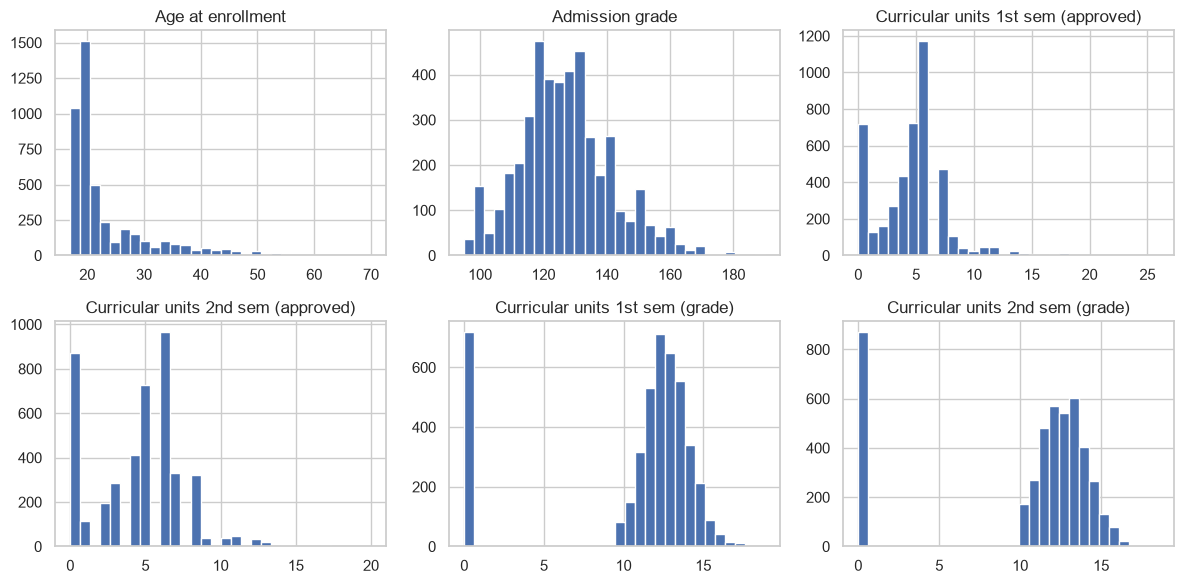

In [7]:
cols = ["Age at enrollment", "Admission grade", "Curricular units 1st sem (approved)",
        "Curricular units 2nd sem (approved)", "Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)"]
df[cols].hist(bins=30, figsize=(12, 6), layout=(2, 3))
plt.tight_layout()
plt.show()

In [8]:
for col in ["Age at enrollment", "Admission grade", "Curricular units 1st sem (evaluations)"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    outside = df[col].lt(q1 - 1.5*(q3-q1)) | df[col].gt(q3 + 1.5*(q3-q1))
    print(col, "медиана:", round(df[col].median(), 2),
          "IQR:", int(outside.sum()), "доля, %:", round(100 * outside.mean(), 2))

Age at enrollment медиана: 20.0 IQR: 441 доля, %: 9.97
Admission grade медиана: 126.1 IQR: 86 доля, %: 1.94
Curricular units 1st sem (evaluations) медиана: 8.0 IQR: 158 доля, %: 3.57


Возраст - от 17 до 70 лет (медиана 20), вступительный балл - от 95 до 190 (медиана 126,1). По правилу 1,5 IQR отмечены 441 возрастное значение (9,97%), 86 вступительных баллов (1,94%) и 158 значений числа оцениваний первого семестра (3,57%). Нулевые средние оценки совпадают с нулём зачтённых дисциплин: 718 записей за первый семестр, 870 - за второй.

## 5. Категориальные признаки и связь с таргетом

Размеры групп и доля `Dropout` по исходным кодам.

In [9]:
categories = ["Debtor", "Tuition fees up to date", "Scholarship holder", "Gender",
              "International", "Displaced", "Daytime/evening attendance\t"]
for col in categories:
    g = df.groupby(col)["Target"].agg(size="size", dropout=lambda x: x.eq("Dropout").mean() * 100)
    print("\n", repr(col))
    display(g.round(2).rename(columns={"size":"Студентов", "dropout":"Dropout, %"}))


 'Debtor'


,Студентов,"Dropout, %"
Debtor,,
0,3921,28.28
1,503,62.03



 'Tuition fees up to date'


,Студентов,"Dropout, %"
Tuition fees up to date,,
0,528,86.55
1,3896,24.74



 'Scholarship holder'


,Студентов,"Dropout, %"
Scholarship holder,,
0,3325,38.71
1,1099,12.19


... (4 outputs left out)


 'Displaced'


,Студентов,"Dropout, %"
Displaced,,
0,1998,37.64
1,2426,27.58



 'Daytime/evening attendance\t'


,Студентов,"Dropout, %"
Daytime/evening attendance\t,,
0,483,42.86
1,3941,30.80


In [10]:
for col in ["Course", "Application mode", "Marital status", "Nacionality"]:
    g = df.groupby(col)["Target"].agg(size="size", dropout=lambda x: x.eq("Dropout").mean() * 100)
    print("\n", col, "категорий:", len(g))
    display(g.sort_values("size", ascending=False).head(8).round(2))


 Course категорий: 17


,size,dropout
Course,,
9500,766,15.40
9147,380,35.26
9238,355,18.31
9085,337,26.71
9773,331,30.51
9991,268,50.75
9670,268,35.45
9254,252,38.10



 Application mode категорий: 18


,size,dropout
Application mode,,
1,1708,20.20
17,872,29.36
39,785,55.41
43,312,36.86
44,213,29.58
7,139,61.15
18,124,36.29
42,77,44.16



 Marital status категорий: 6


,size,dropout
Marital status,,
1,3919,30.21
2,379,47.23
4,91,46.15
5,25,44.00
6,6,66.67
3,4,25.00



 Nacionality категорий: 21


,size,dropout
Nacionality,,
1,4314,32.20
41,38,36.84
26,14,7.14
6,13,30.77
22,13,30.77
24,5,20.00
100,3,66.67
11,3,0.00


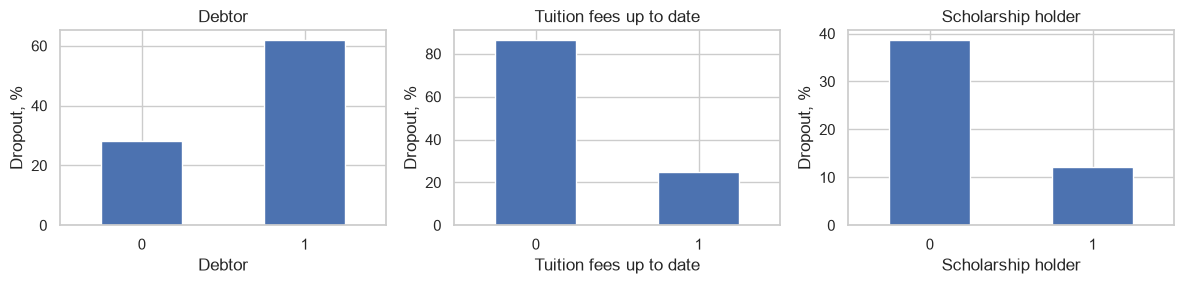

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for col, ax in zip(["Debtor", "Tuition fees up to date", "Scholarship holder"], axes):
    g = df.groupby(col)["Target"].apply(lambda x: x.eq("Dropout").mean() * 100)
    g.plot.bar(ax=ax, rot=0)
    ax.set_title(col)
    ax.set_ylabel("Dropout, %")
plt.tight_layout()
plt.show()

При `Debtor = 1` доля `Dropout` - 62,03%, при `0` - 28,28%. Для `Tuition fees up to date = 0` - 86,55%, при `1` - 24,74%. Для `Scholarship holder = 1` - 12,19%, при `0` - 38,71%. Значения отражают связь с исходом, а не причинное влияние. `Course` содержит 17 кодов, `Application mode` - 18; группы неравны по размеру.

## 6. Первый и второй семестры

Сравнение итогов обучения между классами и проверка нулей.

In [12]:
sem_cols = [f"Curricular units {sem} sem ({metric})" for sem in ["1st", "2nd"]
            for metric in ["enrolled", "evaluations", "approved", "grade"]]
display(df.groupby("Target")[sem_cols].median().T.round(2))

Target,Dropout,Enrolled,Graduate
Curricular units 1st sem (enrolled),6.00,6.0,6.0
Curricular units 1st sem (evaluations),8.00,9.0,8.0
Curricular units 1st sem (approved),2.00,5.0,6.0
Curricular units 1st sem (grade),10.93,12.0,13.0
Curricular units 2nd sem (enrolled),6.00,6.0,6.0
Curricular units 2nd sem (evaluations),7.00,9.0,8.0
Curricular units 2nd sem (approved),0.00,4.0,6.0
Curricular units 2nd sem (grade),0.00,12.0,13.0


In [13]:
zero_second = df["Curricular units 2nd sem (approved)"].eq(0)
counts = pd.crosstab(zero_second, df["Target"])
shares = pd.crosstab(zero_second, df["Target"], normalize="index") * 100
print("Количество по нулю одобренных дисциплин во 2-м семестре:")
display(counts)
print("Доля по строке, %:")
display(shares.round(2))

Количество по нулю одобренных дисциплин во 2-м семестре:


Target,Dropout,Enrolled,Graduate
Curricular units 2nd sem (approved),,,
False,694,726,2134
True,727,68,75


Доля по строке, %:


Target,Dropout,Enrolled,Graduate
Curricular units 2nd sem (approved),,,
False,19.53,20.43,60.05
True,83.56,7.82,8.62


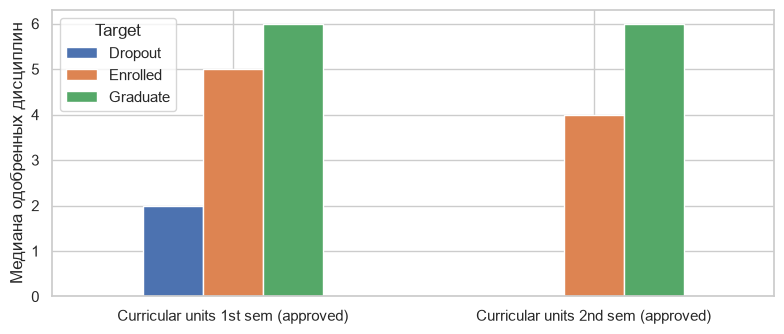

In [14]:
approved = ["Curricular units 1st sem (approved)", "Curricular units 2nd sem (approved)"]
df.groupby("Target")[approved].median().T.plot.bar(figsize=(8, 3.5), rot=0)
plt.ylabel("Медиана одобренных дисциплин")
plt.tight_layout()
plt.show()

Медианы одобренных дисциплин первого/второго семестра: `Dropout` - 2/0, `Enrolled` - 5/4, `Graduate` - 6/6. При нуле одобренных дисциплин во втором семестре (870 студентов) доля `Dropout` составляет 83,56%, при положительном количестве (3 554 студента) - 19,53%. Эти признаки не будут доступны при прогнозе в момент поступления.

## 7. Корреляции и парные графики

Связь числовых измерений с индикатором `Dropout` и между собой.

In [15]:
numeric = ["Age at enrollment", "Admission grade", "Previous qualification (grade)",
           "Curricular units 1st sem (enrolled)", "Curricular units 1st sem (approved)",
           "Curricular units 1st sem (grade)", "Curricular units 2nd sem (enrolled)",
           "Curricular units 2nd sem (approved)", "Curricular units 2nd sem (grade)",
           "Unemployment rate", "Inflation rate", "GDP"]
work = df[numeric].assign(dropout=df["Target"].eq("Dropout").astype(int))
print(work.corr()["dropout"].drop("dropout").sort_values().round(3).to_string())
print("Корреляция оценок 1/2 семестра:", round(df[numeric[5]].corr(df[numeric[8]]), 3))
print("Корреляция одобренных 1/2 семестра:", round(df[numeric[4]].corr(df[numeric[7]]), 3))

Curricular units 2nd sem (grade)      -0.572
Curricular units 2nd sem (approved)   -0.570
Curricular units 1st sem (grade)      -0.481
Curricular units 1st sem (approved)   -0.479
Curricular units 2nd sem (enrolled)   -0.142
Curricular units 1st sem (enrolled)   -0.125
Admission grade                       -0.096
Previous qualification (grade)        -0.078
GDP                                   -0.046
Unemployment rate                      0.013
Inflation rate                         0.028
Age at enrollment                      0.254
Корреляция оценок 1/2 семестра: 0.837
Корреляция одобренных 1/2 семестра: 0.904


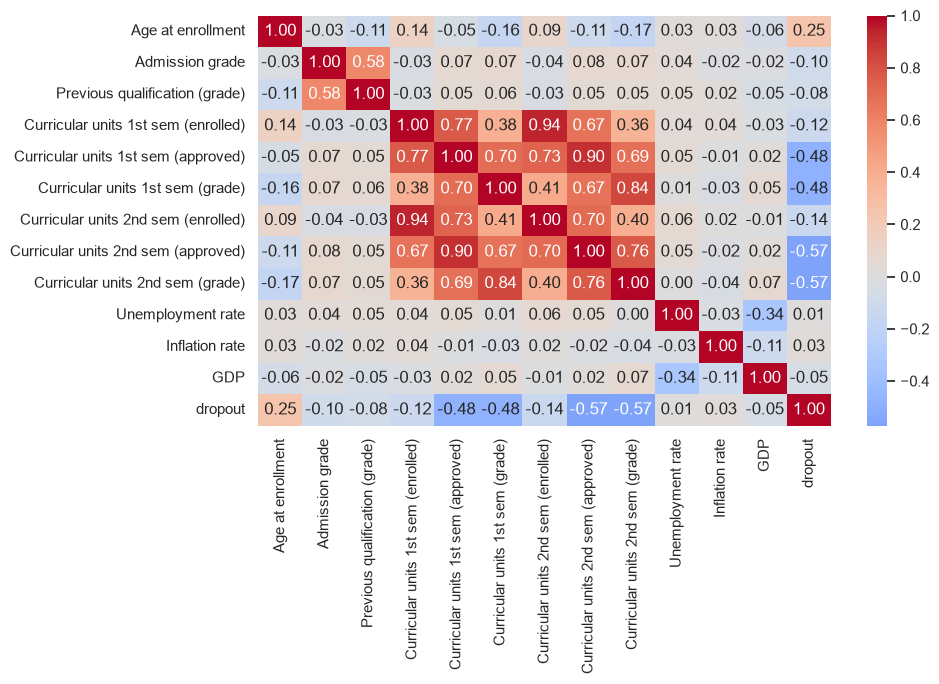

In [16]:
plt.figure(figsize=(10, 7))
sns.heatmap(work.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.tight_layout()
plt.show()

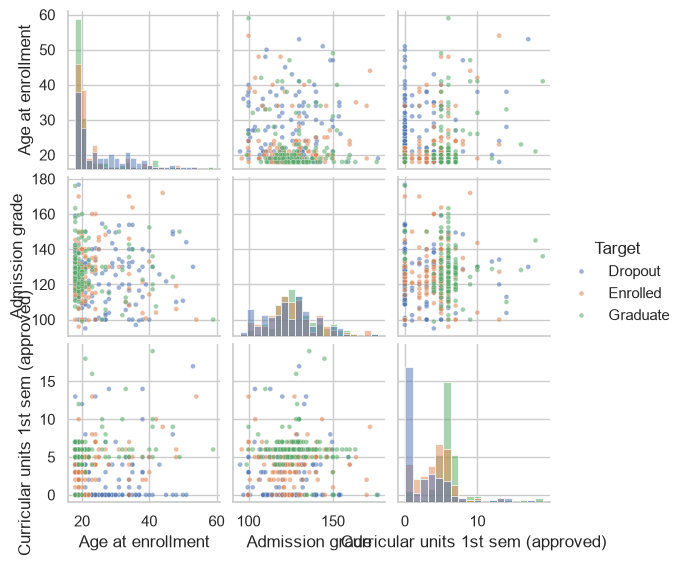

In [17]:
sample = pd.concat([df.loc[df["Target"].eq(label)].sample(140, random_state=42)
                    for label in ["Dropout", "Enrolled", "Graduate"]])
sns.pairplot(sample[["Age at enrollment", "Admission grade", "Curricular units 1st sem (approved)", "Target"]],
             hue="Target", diag_kind="hist", height=1.9,
             plot_kws={"alpha": 0.55, "s": 12})
plt.show()

Между оценками первого и второго семестров корреляция около 0,837, между числами одобренных дисциплин - около 0,904. Наибольшие связи с индикатором `Dropout` среди рассмотренных измерений связаны с успеваемостью; графики показывают распределения без учёта причинных зависимостей. `pairplot` использует по 140 студентов каждого класса, поэтому по нему нельзя оценивать исходные доли классов.

## 8. Момент прогноза и структура наблюдений

Какие группы признаков доступны при поступлении и какие появляются в ходе обучения.

In [18]:
at_enrollment = ["Application mode", "Admission grade", "Age at enrollment", "Course"]
sem1 = [c for c in df if c.startswith("Curricular units 1st sem")]
sem2 = [c for c in df if c.startswith("Curricular units 2nd sem")]
print("Примеры признаков при поступлении:", at_enrollment)
print("Признаков 1-го семестра:", len(sem1))
print("Признаков 2-го семестра:", len(sem2))
print("Идентификаторы студентов или календарные даты в таблице:",
      [c for c in df if c.lower() in ["student_id", "id", "date", "year", "cohort"]])

Примеры признаков при поступлении: ['Application mode', 'Admission grade', 'Age at enrollment', 'Course']
Признаков 1-го семестра: 6
Признаков 2-го семестра: 6
Идентификаторы студентов или календарные даты в таблице: []


При прогнозе до начала обучения показатели обоих семестров недоступны. После первого семестра можно использовать только уже полученные оценки, результаты второго остаются недоступными. Статусы оплаты, задолженности и стипендии также требуют уточнения даты фиксации. 

## 9. Выводы и эталон для агента

- **Таргет:** `Target` с тремя исходами - `Dropout`, `Enrolled`, `Graduate`.
- **Тип задачи:** многоклассовая классификация; бинарную задачу отчисления согласовывать отдельно.
- **Дисбаланс:** `Enrolled` - 17,95%, `Dropout` - 32,12%, `Graduate` - 49,93%.
- **Пропуски:** формальных `NaN` нет; нули академических показателей интерпретировать по смыслу.
- **Коды:** целочисленные поля поступления, курса и статусов считать категориями, а не непрерывной шкалой.
- **Выбросы:** не удалять взрослых студентов и необычные оценки только по формальному IQR.
- **Связь с таргетом:** учитывать академические показатели и признаки финансового статуса без вывода о причинности.
- **Момент прогноза:** различать прогноз при поступлении, после первого и после второго семестра.
- **Метрика:** учитывать редкий класс и назначение прогноза, возможны macro-F1 и recall по `Dropout`.
- **Валидация:** в файле нет идентификаторов и календарных дат для проверки на новых наборах студентов; нужно явно фиксировать ограничение оценки.
